In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/winequality-white.csv", sep=';')

In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [4]:
df.shape

(4898, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [6]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(937)

In [8]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [9]:
df["quality"].value_counts().sort_index()

quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64

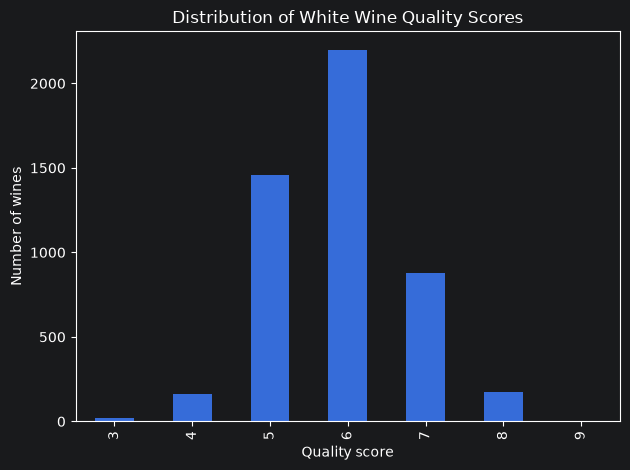

In [10]:
import matplotlib.pyplot as plt

df["quality"].value_counts().sort_index().plot(
    kind="bar",
    xlabel="Quality score",
    ylabel="Number of wines",
    title="Distribution of White Wine Quality Scores",
)

plt.tight_layout()
plt.show()

In [11]:
df.shape, df.drop_duplicates().shape

((4898, 12), (3961, 12))

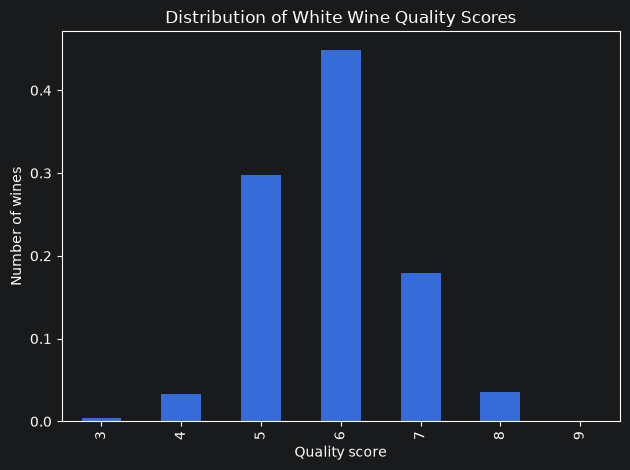

In [18]:


df["quality"].value_counts(normalize=True).sort_index().plot(
    kind="bar",
    xlabel="Quality score",
    ylabel="Number of wines",
    title="Distribution of White Wine Quality Scores",
)

plt.tight_layout()
plt.show()

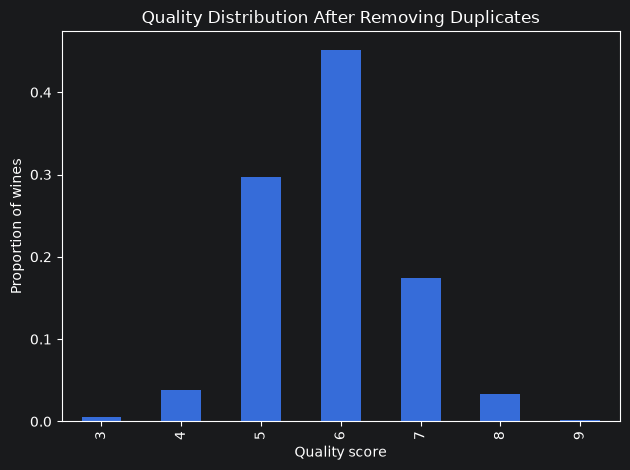

In [22]:
df.drop_duplicates()["quality"].value_counts(normalize=True).sort_index().plot(
    kind="bar",
    xlabel="Quality score",
    ylabel="Proportion of wines",
    title="Quality Distribution After Removing Duplicates"
)

plt.tight_layout()
plt.show()

In [23]:
original_dataset = df["quality"].value_counts(normalize=True).sort_index()

In [24]:
deduplicated_dataset = df.drop_duplicates()["quality"].value_counts(normalize=True).sort_index()

In [25]:
duplicate_values = original_dataset - deduplicated_dataset

In [26]:
duplicate_values

quality
3   -0.000966
4   -0.005348
5    0.000826
6   -0.002647
7    0.005719
8    0.002656
9   -0.000241
Name: proportion, dtype: float64

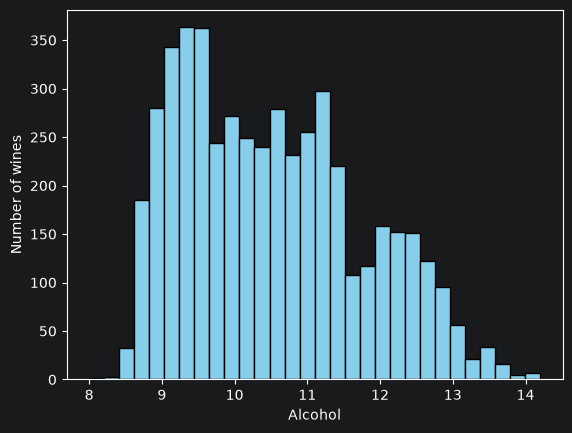

In [30]:
plt.hist(df["alcohol"], bins=30, color="skyblue", edgecolor="black")
plt.xlabel("Alcohol")
plt.ylabel("Number of wines")
plt.show()

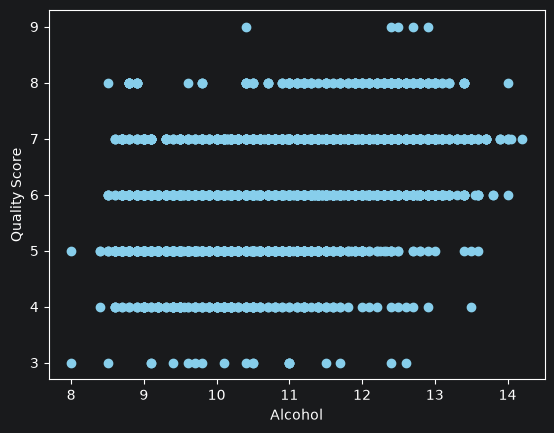

In [31]:
plt.scatter(df["alcohol"], df["quality"], color="skyblue", marker="o")
plt.xlabel("Alcohol")
plt.ylabel("Quality Score")
plt.show()

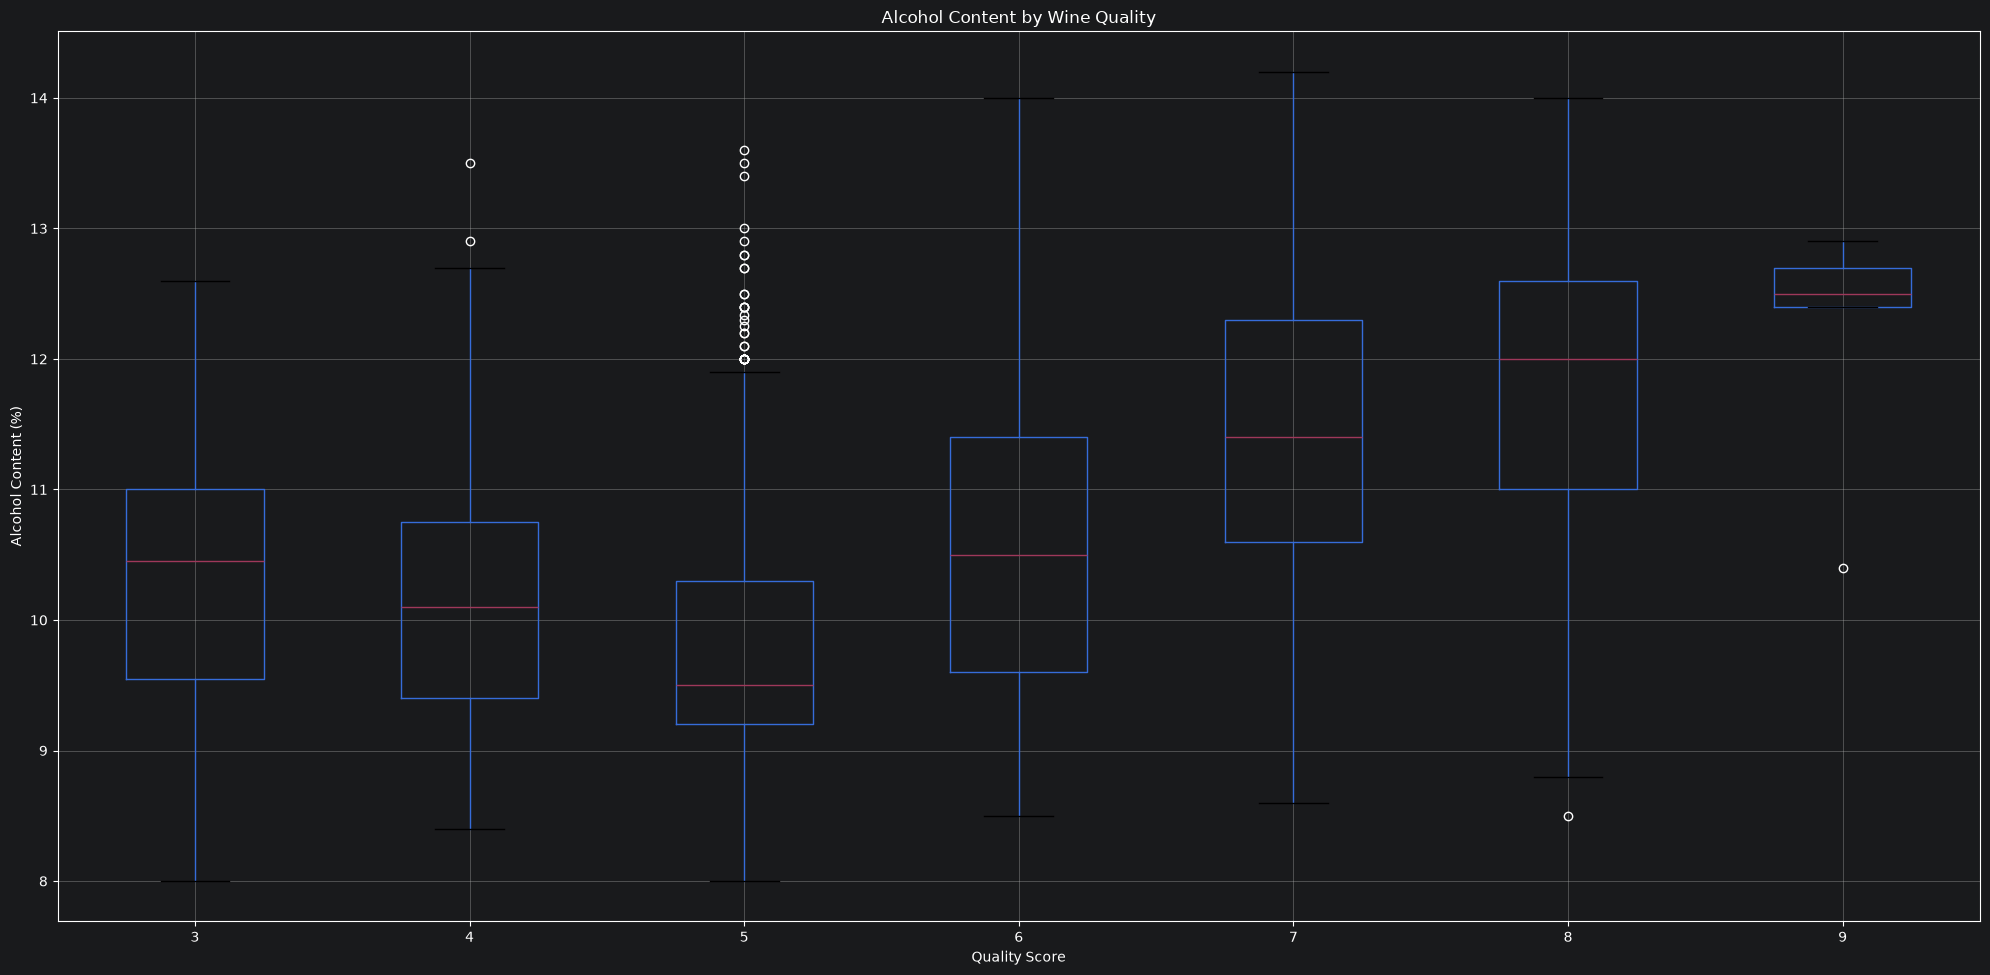

In [33]:
df.boxplot(column="alcohol", by="quality", figsize=(20, 10))
plt.title("Alcohol Content by Wine Quality")
plt.suptitle("")
plt.xlabel("Quality Score")
plt.ylabel("Alcohol Content (%)")
plt.tight_layout()
plt.show()

In [34]:
corr_mat = df["alcohol"].corr(df["quality"])
print(corr_mat)

0.43557471546137283


In [35]:
corr_matrix_all = df.corr(numeric_only=True)
quality_corr = corr_matrix_all["quality"].sort_index(ascending=False)
print(quality_corr)

volatile acidity       -0.194723
total sulfur dioxide   -0.174737
sulphates               0.053678
residual sugar         -0.097577
quality                 1.000000
pH                      0.099427
free sulfur dioxide     0.008158
fixed acidity          -0.113663
density                -0.307123
citric acid            -0.009209
chlorides              -0.209934
alcohol                 0.435575
Name: quality, dtype: float64


<Axes: >

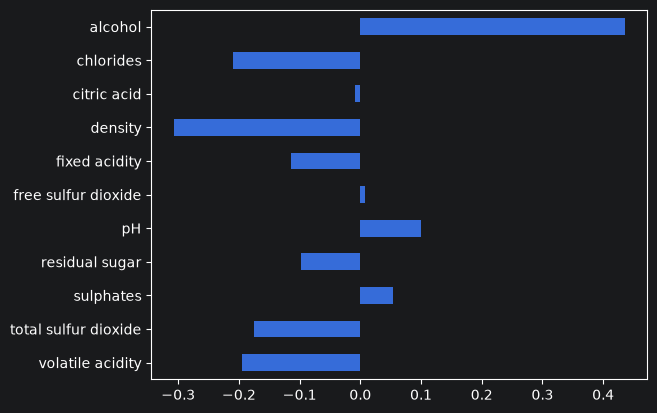

In [38]:
corr_graph = quality_corr.drop("quality")
corr_graph.plot(kind="barh")